# Dự báo Netflix theo Month, Quarter và Type

Mô hình tháng gốc giữ tổng forecast. Mô hình đa biến dùng `month_index + quarter + type` để chia forecast cho Movie và TV Show.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent

## 1. Chuẩn bị dữ liệu

In [2]:
titles = pd.read_csv(
    ROOT / 'data/normalized/dim_title.csv',
    usecols=['date_added', 'type'],
)
titles['date_added'] = pd.to_datetime(titles['date_added'], errors='coerce')
titles = titles.dropna(subset=['date_added', 'type'])
titles['month'] = titles['date_added'].dt.to_period('M').dt.to_timestamp()

train = titles[titles['month'] < '2021-01-01']
monthly = (
    train.groupby(['month', 'type']).size()
    .rename('monthly_additions').reset_index()
)

months = pd.DataFrame({'month': pd.date_range('2011-01-01', '2020-12-01', freq='MS')})
types = pd.DataFrame({'type': sorted(train['type'].unique())})
df = (
    months.assign(key=1).merge(types.assign(key=1), on='key')
    .drop(columns='key').merge(monthly, on=['month', 'type'], how='left')
)
df['monthly_additions'] = df['monthly_additions'].fillna(0)
df['month_index'] = (df['month'].dt.year - 2011) * 12 + df['month'].dt.month - 1
df['quarter'] = 'Q' + df['month'].dt.quarter.astype(str)

df.head()

,month,type,monthly_additions,month_index,quarter
0,2011-01-01,Movie,0.0,0,Q1
1,2011-01-01,TV Show,0.0,0,Q1
2,2011-02-01,Movie,0.0,1,Q1
3,2011-02-01,TV Show,0.0,1,Q1
4,2011-03-01,Movie,0.0,2,Q1


## 2. Huấn luyện mô hình

In [3]:
features = ['month_index', 'quarter', 'type']

preprocessor = ColumnTransformer(
    [('category', OneHotEncoder(drop='first', handle_unknown='ignore'), ['quarter', 'type'])],
    remainder='passthrough',
)
detail_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression()),
])
detail_model.fit(df[features], df['monthly_additions'])

# Mô hình tổng giống notebook 03.
baseline = pd.read_csv(ROOT / 'data/normalized/fact_monthly_addition.csv')
baseline_model = LinearRegression().fit(
    baseline[['month_index']], baseline['monthly_additions']
)

print('Đã huấn luyện:', features)

Đã huấn luyện: ['month_index', 'quarter', 'type']


## 3. Dự báo 9 tháng và đối soát tổng

In [4]:
future_months = pd.DataFrame({
    'month': pd.date_range('2021-01-01', '2021-09-01', freq='MS')
})
future = (
    future_months.assign(key=1).merge(types.assign(key=1), on='key')
    .drop(columns='key')
)
future['month_index'] = (future['month'].dt.year - 2011) * 12 + future['month'].dt.month - 1
future['quarter'] = 'Q' + future['month'].dt.quarter.astype(str)

future['raw_forecast'] = np.clip(detail_model.predict(future[features]), 0, None)
future['baseline_forecast'] = baseline_model.predict(future[['month_index']])
raw_total = future.groupby('month')['raw_forecast'].transform('sum')
future['forecast'] = future['raw_forecast'] * future['baseline_forecast'] / raw_total

future.head()

,month,type,month_index,quarter,raw_forecast,baseline_forecast,forecast
0,2021-01-01,Movie,120,Q1,99.200897,170.185434,97.239358
1,2021-01-01,TV Show,120,Q1,74.417564,170.185434,72.946076
2,2021-02-01,Movie,121,Q1,100.103603,171.993733,98.146234
3,2021-02-01,TV Show,121,Q1,75.320270,171.993733,73.847500
4,2021-03-01,Movie,122,Q1,101.006310,173.802033,99.053053


## 4. Đánh giá bằng MAE và RMSE

In [5]:
actual_source = pd.read_csv(
    ROOT / 'data/processed/netflix_titles.csv',
    usecols=['date_added', 'type'],
)
actual_source['date_added'] = pd.to_datetime(actual_source['date_added'], errors='coerce')
actual_source['month'] = actual_source['date_added'].dt.to_period('M').dt.to_timestamp()
actual = (
    actual_source[actual_source['date_added'].between('2021-01-01', '2021-09-30')]
    .groupby(['month', 'type']).size().rename('actual').reset_index()
)
result = future.merge(actual, on=['month', 'type'], how='left')
result['actual'] = result['actual'].fillna(0)
result['residual'] = result['actual'] - result['forecast']

total = result.groupby('month')[['actual', 'forecast']].sum()
error = total['actual'] - total['forecast']
mae = error.abs().mean()
rmse = np.sqrt(error.pow(2).mean())

print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')

MAE: 36.78
RMSE: 44.76


## 5. Biểu đồ

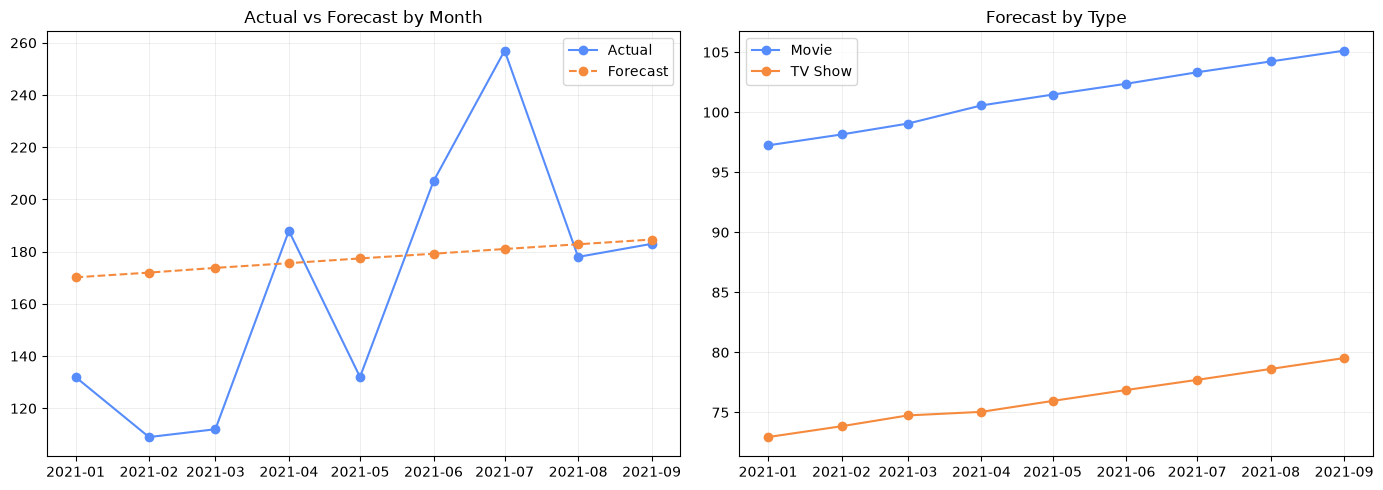

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(total.index, total['actual'], marker='o', label='Actual')
axes[0].plot(total.index, total['forecast'], marker='o', linestyle='--', label='Forecast')
axes[0].set_title('Actual vs Forecast by Month')
axes[0].legend()
axes[0].grid(alpha=0.3)

for content_type, group in result.groupby('type'):
    axes[1].plot(group['month'], group['forecast'], marker='o', label=content_type)
axes[1].set_title('Forecast by Type')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Xuất một file cho Power BI

In [7]:
output = result[[
    'month', 'quarter', 'type', 'actual', 'forecast', 'residual'
]].copy()
output['absolute_error'] = output['residual'].abs()
output['squared_error'] = output['residual'].pow(2)

output_path = ROOT / 'data/model_outputs/powerbi_forecast_quarter_type.csv'
output.to_csv(output_path, index=False)
print('Đã xuất:', output_path)

Đã xuất: C:\Users\hoc\Documents\3\TTDLTQ\PJCK\Project_DataVisualization\data\model_outputs\powerbi_forecast_quarter_type.csv


**Kết quả:** Khi Quarter và Type đều là Tất cả, MAE = 36.78 và RMSE = 44.76. Khi lọc Quarter hoặc Type trong Power BI, hai chỉ số được tính lại theo dữ liệu đang lọc.